# Differentiation potential with CytoTRACE (dynbenchmark port)

**CytoTRACE** ([Gulati 2020](https://doi.org/10.1126/science.aax0249)) exploits the fact that **less-differentiated cells express more genes**. It scores each cell on its gene-count correlate of stemness, then smooths the score over a kNN graph. The result is a single-axis differentiation potential — useful as a sanity check on directionality even before you pick a topology.

This tutorial uses the **dynbenchmark port** [`pycytotrace-bio`](https://pypi.org/project/pycytotrace-bio/) (a scoped Python implementation; see the validation limitations below). For the CytoTrace 2 implementation packaged inside omicverse, see [`t_cytotrace2.ipynb`](t_cytotrace2.ipynb).

## Install

```bash
pip install omicverse[trajectory]
```

### Reproducible software revision

This corrected example requires the input-identifier forwarding merged in OmicVerse #1043 and the CytoTRACE repair in hurry060215-tech/py-CytoTRACE#1. PyPI pycytotrace-bio 0.1.0 predates that backend repair. Until an upstream release includes it, use the reviewed source revision explicitly:

```bash
python -m pip install "git+https://github.com/hurry060215-tech/py-CytoTRACE.git@62b59509dee90147a24073ede4f17cd5883ac58f"
```

Use an OmicVerse source revision containing commit `2f887e3e`; OmicVerse 2.4.3 predates that integration fix. The executed example is a 300-cell teaching subset retaining all genes, not a full-cohort or biological-validation claim.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import omicverse as ov
ov.plot_set()

D:\Anaconda3\envs\omicverse\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)


🔬 Starting plot initialization...
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 1
    • [CUDA 0] NVIDIA GeForce RTX 5060 Ti
      Memory: 15.9 GB | Compute: 12.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.1   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
adata = ov.datasets.pancreatic_endocrinogenesis()
# Deterministic 300-cell teaching subset; retain every measured gene.
# Exact NNLS scales poorly with cell count; this is not a full-cohort run.
selected = np.sort(np.random.default_rng(17).choice(adata.n_obs, 300, replace=False))
adata = adata[selected].copy()
cytotrace_input = adata.copy()
cytotrace_input.layers['counts'] = cytotrace_input.X.copy()
print('CytoTRACE input:', cytotrace_input.shape)

🔍 Downloading data to ./data\endocrinogenesis_day15.h5ad...


Downloading:   0%|          | 0.00/52.5M [00:00<?, ?B/s]

Downloading:   0%|          | 90.1k/52.5M [00:00<01:03, 828kB/s]

Downloading:   1%|          | 303k/52.5M [00:00<00:44, 1.17MB/s]

Downloading:   2%|▏         | 934k/52.5M [00:00<00:16, 3.09MB/s]

Downloading:   3%|▎         | 1.69M/52.5M [00:00<00:10, 4.62MB/s]

... (128 outputs left out)

Downloading: 100%|█████████▉| 52.4M/52.5M [00:15<00:00, 3.94MB/s]

Downloading: 100%|██████████| 52.5M/52.5M [00:15<00:00, 3.42MB/s]

✅ Download completed
 Loading data from ./data\endocrinogenesis_day15.h5ad


✅ Successfully loaded: 3696 cells × 27998 genes
CytoTRACE input: (300, 27998)


In [3]:
# The dataset already provides PCA and UMAP for visualization.
# Do not normalize or restrict the gene set before CytoTRACE.
assert 'X_pca' in adata.obsm and 'X_umap' in adata.obsm
assert cytotrace_input.n_vars == 27998

The supplied PCA and UMAP are used only to display this reproducible 300-cell subset. CytoTRACE itself receives all 27,998 genes and raw counts.

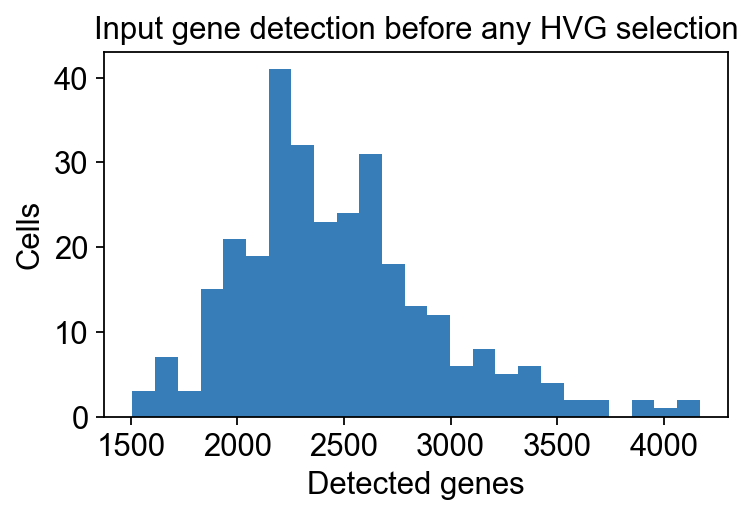

In [4]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(np.asarray(cytotrace_input.layers['counts'].getnnz(axis=1)), bins=25, color='#377eb8')
ax.set(xlabel='Detected genes', ylabel='Cells', title='Input gene detection before any HVG selection')
plt.show()

X_umap converted to UMAP to visualize and saved to adata.obsm['UMAP']
if you want to use X_umap, please set convert=False


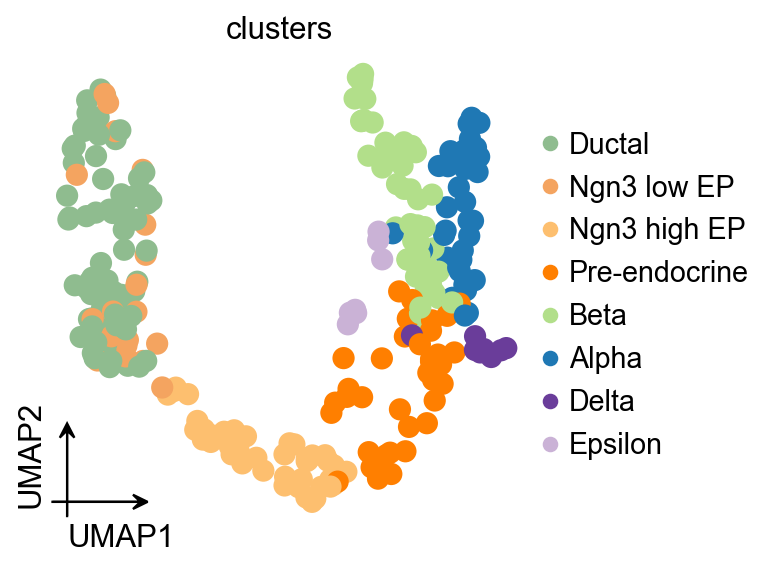

In [5]:
ov.pl.umap(
    adata,
    color='clusters'
)

CytoTRACE receives raw counts and the full gene set. A counts layer on an HVG-subset object is itself subset, and cannot recover missing genes. The UMAP is a supplied visualization; the CytoTRACE scores do not use it. Batch correction and fast subsampling are outside this port.

## CytoTRACE

In [6]:
Traj=ov.single.TrajInfer(
    cytotrace_input,
    basis='X_umap',
    groupby='clusters',
    use_rep='X_pca',
    n_comps=50,
)
Traj.set_origin_cells('Ductal')

In [7]:
Traj.inference(method='cytotrace')
# Align by cell identifiers rather than assuming row order.
for key in ["cytotrace_stemness", "cytotrace_pseudotime"]:
    adata.obs[key] = cytotrace_input.obs[key].reindex(adata.obs_names)

## Visualize pseudotime on UMAP

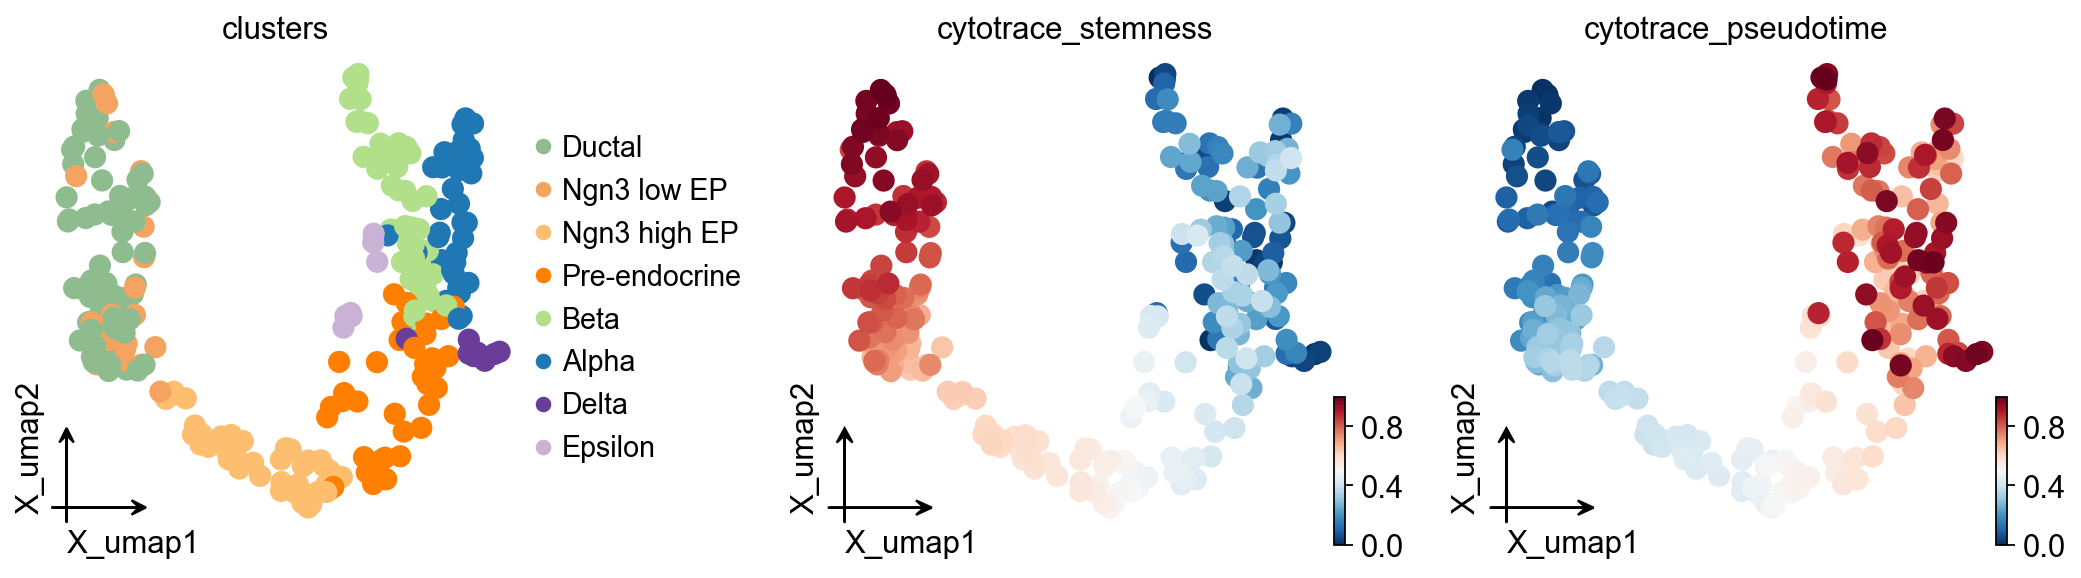

In [8]:
ov.pl.embedding(
    adata, basis='X_umap',
    color=['clusters', 'cytotrace_stemness', 'cytotrace_pseudotime'],
    frameon='small',
    cmap='RdBu_r',
    ncols=3,
)

## Interpretation and validation

`cytotrace_stemness` is higher for less differentiated predictions; `cytotrace_pseudotime = 1 - stemness` reverses that polarity. These are relative scores within this 300-cell subset, not calibrated developmental time. The origin label does not influence CytoTRACE. Do not force an expected Ductal ranking or interpret a UMAP pattern as an R-parity test.

Direct R/Python comparisons are available in the standalone package's `examples/real_marrow_R_parity.ipynb`: 120 real marrow cells with the complete gene axis, plus ERCC and low-quality-cell controls. That evidence does not establish full-cohort, batch-mode, or fast-mode equivalence.

## Reference

- Saelens W. et al. *A comparison of single-cell trajectory inference methods.* Nat Biotechnol **37**, 547–554 (2019). [doi:10.1038/s41587-019-0071-9](https://doi.org/10.1038/s41587-019-0071-9)
- Recommended backend (Slingshot): [t_traj_recommended](../t_traj_slingshot.ipynb)
- All zoo backends: [zoo/index](index.md)